In [648]:
import numpy as np
import json
import re
from konlpy.tag import Okt
from kiwipiepy import Kiwi
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib import font_manager, rc
from wordcloud import WordCloud
import pandas as pd
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import matplotlib
import numpy as np
import matplotlib
import warnings
warnings.filterwarnings(action='ignore')
import folium
import seaborn as sns

In [649]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

import matplotlib.pyplot as plt
import seaborn as sns

In [650]:
df =  pd.read_csv('./11장_data/UCI_Credit_Card.csv', header=0, encoding='CP949', engine='python')
print(df.describe) #작업 확인용 출력

<bound method NDFrame.describe of           ID  LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  \
0          1    20000.0    2          2         1   24      2      2     -1   
1          2   120000.0    2          2         2   26     -1      2      0   
2          3    90000.0    2          2         2   34      0      0      0   
3          4    50000.0    2          2         1   37      0      0      0   
4          5    50000.0    1          2         1   57     -1      0     -1   
...      ...        ...  ...        ...       ...  ...    ...    ...    ...   
29995  29996   220000.0    1          3         1   39      0      0      0   
29996  29997   150000.0    1          3         2   43     -1     -1     -1   
29997  29998    30000.0    1          2         2   37      4      3      2   
29998  29999    80000.0    1          3         1   41      1     -1      0   
29999  30000    50000.0    1          2         1   46      0      0      0   

       PAY_4  ...

In [651]:
df.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default.payment.next.month'],
      dtype='object')

In [652]:
df.rename(columns={'default.payment.next.month': 'default'}, inplace=True)

In [653]:
df.head(3)

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0


In [654]:
df.shape

(30000, 25)

In [655]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         30000 non-null  int64  
 1   LIMIT_BAL  30000 non-null  float64
 2   SEX        30000 non-null  int64  
 3   EDUCATION  30000 non-null  int64  
 4   MARRIAGE   30000 non-null  int64  
 5   AGE        30000 non-null  int64  
 6   PAY_0      30000 non-null  int64  
 7   PAY_2      30000 non-null  int64  
 8   PAY_3      30000 non-null  int64  
 9   PAY_4      30000 non-null  int64  
 10  PAY_5      30000 non-null  int64  
 11  PAY_6      30000 non-null  int64  
 12  BILL_AMT1  30000 non-null  float64
 13  BILL_AMT2  30000 non-null  float64
 14  BILL_AMT3  30000 non-null  float64
 15  BILL_AMT4  30000 non-null  float64
 16  BILL_AMT5  30000 non-null  float64
 17  BILL_AMT6  30000 non-null  float64
 18  PAY_AMT1   30000 non-null  float64
 19  PAY_AMT2   30000 non-null  float64
 20  PAY_AM

In [656]:
from sklearn.preprocessing import StandardScaler

In [657]:
Y = df['default']
X = df.drop(['ID','default'],axis=1)

In [658]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3, random_state = 0)

In [659]:
scaler = StandardScaler()
#각각의 연스보가 테스트 값들을 표준화
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
#class_weight='balanced'
#옵션 있는버전 class_weight='balanced'
#기존은 정상 고객틀릴때와 연체자 틀릴때 똑같은 페널티를 부과했다면
#이 옵션을 사용하면 연체자를 틀릴때 몇배 더 큰 페널티 부여
# lr_b_credit = LogisticRegression(class_weight='balanced')
#기존
lr_b_credit = LogisticRegression()
#모듈에 넣고 돌린다.
lr_b_credit.fit(X_train, Y_train);
#예측값 저장
Y_predict = lr_b_credit.predict(X_test)

In [660]:
accuracy = accuracy_score(Y_test, Y_predict)
precision = precision_score(Y_test, Y_predict)
recall = recall_score(Y_test, Y_predict)
f1 = f1_score(Y_test, Y_predict)
roc_auc = roc_auc_score(Y_test, Y_predict)

In [661]:
confusion_matrix(Y_test, Y_predict)

array([[6897,  163],
       [1494,  446]])

In [662]:
print( '정확도: {0:.3f}, 정밀도: {1:.3f}, 재현율: {2:.3f}, F1: {3:.3f}'.format(accuracy,precision,recall,f1))
#정확도는 높다 정밀도 또한 높다 하지만 재현율이 낮다.
#전체 연체자가 100명이면 23명만 잡고 나머지는 놓쳤다.

정확도: 0.816, 정밀도: 0.732, 재현율: 0.230, F1: 0.350


In [663]:
print('ROC_AUC: {0:.3f}'.format(roc_auc))
#이 로지스틱 모델의 경우 0.5가 미니멈이기 때문에 찍는것보다는 조금 나은 수준이라고 볼 수 있다.

ROC_AUC: 0.603


In [664]:
#옵션있는버전
confusion_matrix(Y_test, Y_predict)
#확실히 tp에 해당하는 경우가 많아지고 대신 연체자라고 예상했지만 네거티브인 경우도 많아짐

array([[6897,  163],
       [1494,  446]])

In [665]:
print( '정확도: {0:.3f}, 정밀도: {1:.3f}, 재현율: {2:.3f}, F1: {3:.3f}'.format(accuracy,precision,recall,f1))
#정확도가 낮아지고 정밀도가 현저히 낮아졌다.
#약간의 징조만 보여도 연체자로 판단했기에 정밀도는 낮아졌지만 재현율이 확실히 증가하였다.
#정밀도와 재현율의 혼합점수인 f1도 상승하였다.

정확도: 0.816, 정밀도: 0.732, 재현율: 0.230, F1: 0.350


In [666]:
print('ROC_AUC: {0:.3f}'.format(roc_auc))
#그 전보다는 낫다

ROC_AUC: 0.603


In [667]:
#연체 지수 평균 (지난 6개월간의 연체 상태 평균)
df['PAY_MEAN'] = df[['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']].mean(axis=1)

#청구된 금액 합
df['BILL_AMT_SUM'] = df[['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']].sum(axis=1)
#실제 납부한 금액
df['PAY_AMT_SUM'] = df[['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']].sum(axis=1)

df['PAY_MAX'] = df[['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']].max(axis=1)

In [668]:
drop_columns = [
    'ID', 'default', 
    'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6',
    'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6',
    'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'
]

In [669]:
X = df.drop(drop_columns, axis=1)
Y = df['default']

In [670]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3, random_state = 0)

In [671]:
scaler = StandardScaler()
#각각의 연스보가 테스트 값들을 표준화
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
#class_weight='balanced'
#옵션 있는버전 class_weight='balanced'
#기존은 정상 고객틀릴때와 연체자 틀릴때 똑같은 페널티를 부과했다면
#이 옵션을 사용하면 연체자를 틀릴때 몇배 더 큰 페널티 부여
# lr_b_credit = LogisticRegression(class_weight='balanced')
#기존
lr_b_credit = LogisticRegression()
#모듈에 넣고 돌린다.
lr_b_credit.fit(X_train, Y_train);
#예측값 저장
Y_predict = lr_b_credit.predict(X_test)

In [672]:
accuracy = accuracy_score(Y_test, Y_predict)
precision = precision_score(Y_test, Y_predict)
recall = recall_score(Y_test, Y_predict)
f1 = f1_score(Y_test, Y_predict)
roc_auc = roc_auc_score(Y_test, Y_predict)

In [673]:
confusion_matrix(Y_test, Y_predict)

array([[6914,  146],
       [1539,  401]])

In [674]:
print( '정확도: {0:.3f}, 정밀도: {1:.3f}, 재현율: {2:.3f}, F1: {3:.3f}'.format(accuracy,precision,recall,f1))
#정확도는 높다 정밀도 또한 높다 하지만 재현율이 낮다.
#전체 연체자가 100명이면 23명만 잡고 나머지는 놓쳤다.

정확도: 0.813, 정밀도: 0.733, 재현율: 0.207, F1: 0.322


In [675]:
print('ROC_AUC: {0:.3f}'.format(roc_auc))
#이 로지스틱 모델의 경우 0.5가 미니멈이기 때문에 찍는것보다는 조금 나은 수준이라고 볼 수 있다.

ROC_AUC: 0.593


In [676]:
pip install graphviz

Note: you may need to restart the kernel to use updated packages.


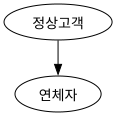

In [677]:
import graphviz

# 간단한 테스트용 트리 구조 생성
dot = graphviz.Digraph(comment='Test')
dot.node('A', '정상고객')
dot.node('B', '연체자')
dot.edge('A', 'B')

# 화면에 출력이 잘 되는지 확인
dot

In [678]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
from sklearn.tree import export_graphviz
from sklearn.tree import DecisionTreeClassifier

In [679]:
titanic = sns.load_dataset("titanic")

In [680]:
titanic.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [681]:
titanic['embarked'].mode()

0    S
Name: embarked, dtype: object

In [682]:
titanic= titanic.drop('deck',axis=1)
#deck는 결측치가 너무 많아서 drop해주었다.

In [683]:
a = titanic['age'].mean()
titanic['age']=titanic['age'].fillna(a)
titanic['embark_town']=titanic['embark_town'].fillna('Southampton')
titanic['embarked']=titanic['embarked'].fillna('S')
#결측치 age는 mean, embark_town과 embarked는 최빈값으로 채워주었다.


In [684]:
titanic.isna().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

In [685]:
titanic[:5]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True


In [686]:
#일단 원핫 인코딩 없이 alive y 값 타겟으로하기
titanic.describe()
#describe시 계산되어 나오는 값들이 numeric값이다.

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,13.002015,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,29.699118,0.000000,0.000000,14.454200
75%,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [687]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

In [688]:
target_columns = ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
titanic = titanic[target_columns]
#위의 numeric값들만 일단 column으로 지정해주었다.

In [689]:
drop_cols = ['PassengerId', 'Name', 'Ticket', 'Cabin', 'alive', 'embark_town', 'class']
le = LabelEncoder()
titanic['sex'] = le.fit_transform(titanic['sex'])
titanic['embarked'] = le.fit_transform(titanic['embarked'].astype(str))
#성별과 embarked는 임의로 숫자로 변경해주고 나머지 문자 값들은 다 드롭해준다.

In [690]:
X= titanic.drop(columns=['survived'])
Y= titanic['survived']
#x는 기존에 드롭한 titanic에 survived를 드롭한 값
#y는 survived컬럼의 데이터로 지정한다.

In [691]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=42)
#모델 학습을 돌린다.

In [692]:
dt_titanic = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_titanic.fit(X_train, Y_train);
Y_predict = dt_titanic.predict(X_test);

In [693]:
accuracy = accuracy_score(Y_test, Y_predict)
print('결정 트리 예측 정확도: {0:.4f}'.format(accuracy))
#2일때 0.7724 3일때 0.8097 8일때 0.7724 10일때 0.7687 30일때 0.7388
#max_depth가 커지면서 오히려 정확도가

결정 트리 예측 정확도: 0.8097


In [694]:
# DecisionTreeClassifier 객체에 설정된 모든 하이퍼파라미터와 현재 값들을 확인
print('결정 트리의 현재 하이퍼 매개변수: \n', dt_titanic.get_params())

결정 트리의 현재 하이퍼 매개변수: 
 {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 3, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}


In [695]:
# 결정 트리의 최대 깊이(max_depth)를 여러 값으로 바꿔가며 
# 교차 검증을 통해 가장 성능이 좋은 모델을 자동으로 찾는 과정
# depth가: 작으면 → 단순 → 과소적합 / 크면 → 복잡 → 과적합
# 트리의 질문 횟수를 바꿔가며 언제 성능이 가장 좋아지는지 확인
params = {
    'max_depth' : [3, 6, 8, 10, 12, 16, 20, 24]
}

grid_cv = GridSearchCV(dt_titanic, # 기본 결정 트리 모델
                       param_grid = params, # 실험할 하이퍼파라미터 목록
                       scoring ='accuracy', # 성능 평가 기준
                       #4개를 학습으로 사용하고 1개는 평가로 사용한다.
                       cv = 5, # 5-fold 교차 검증
                       return_train_score = True) 
# 학습 정확도(train score)도 함께 저장 -> 과적합 여부 시각적으로 확인 가능
grid_cv.fit(X_train, Y_train); # 모델 학습 실행

In [696]:
cv_results_df = pd.DataFrame(grid_cv.cv_results_)
cv_results_df[['param_max_depth', 'mean_test_score', 'mean_train_score']]

,param_max_depth,mean_test_score,mean_train_score
0,3,0.807329,0.836271
1,6,0.794606,0.891655
2,8,0.780142,0.919344
3,10,0.793032,0.941014
4,12,0.786619,0.957872
5,16,0.772168,0.973521
6,20,0.760903,0.983549
7,24,0.760916,0.983951


In [697]:
# grid_cv.best_score_ : GridSearchCV가 찾은 최고 성능 점수 / grid_cv.best_params_ : 최고 성능을 낸 하이퍼파라미터 조합
print('최고 평균 정확도: {0:.4f}, 최적 하이퍼 매개변수: {1}'.format(grid_cv.best_score_, grid_cv.best_params_))

최고 평균 정확도: 0.8073, 최적 하이퍼 매개변수: {'max_depth': 3}


In [698]:
params = {
    'max_depth' : [3, 8, 16, 20],
    'min_samples_split' : [2, 3, 5, 8, 16, 24, 30]
}

grid_cv = GridSearchCV(dt_titanic, 
                       param_grid = params, 
                       scoring ='accuracy', 
                       cv = 5, 
                       return_train_score = True)
grid_cv.fit(X_train, Y_train);
#2, 3, 5, 8, 9, 10, 11등 다양한 숫자를 min_samples로 넣어보았는데 max_depth와 마찬가지로 3일때가 제일 예측정확도가 높았다.

In [699]:
cv_results_df = pd.DataFrame(grid_cv.cv_results_)
cv_results_df[['param_max_depth', 'param_min_samples_split', 'mean_test_score', 'mean_train_score']]
#6번 조합이 train score는 제일 높지만 test_score는 낮은것을 확인 할 수있다.
#그래서 아래 best_score를 정하는것은 test_score와 train_score 그리고 두개의 점수차이를 종합해서 산출한다.

,param_max_depth,param_min_samples_split,mean_test_score,mean_train_score
0,3,2,0.807329,0.836271
1,3,3,0.807329,0.836271
2,3,5,0.807329,0.836271
3,3,8,0.807329,0.836271
4,3,16,0.800890,0.834666
5,3,24,0.796090,0.828646
6,3,30,0.796090,0.828646
7,8,2,0.780142,0.919344
8,8,3,0.783342,0.914129
9,8,5,0.796206,0.907309


In [700]:
print('최고 평균 정확도: {0:.4f}, 최적 하이퍼 매개변수: {1}'.format(grid_cv.best_score_, grid_cv.best_params_))

최고 평균 정확도: 0.8073, 최적 하이퍼 매개변수: {'max_depth': 3, 'min_samples_split': 2}


In [701]:
best_dt_titanic = grid_cv.best_estimator_
#가장 값이 좋았던 도구를 가져온다
best_Y_predict = best_dt_titanic.predict(X_test)
#최고의 도구로 테스트를 돌린다
best_accuracy = accuracy_score(Y_test, best_Y_predict)
#그 예측값이 실제 정답과 얼마나 일치하는지 계산한다.
print('best 결정 트리 예측 정확도: {0:.4f}'.format(best_accuracy))

best 결정 트리 예측 정확도: 0.8097


In [702]:
feature_importance_values = best_dt_titanic.feature_importances_
#학습이 완료된 모델을 가져온다.
feature_importance_values_s = pd.Series(feature_importance_values, 
                                        index = X_train.columns)
#원래 데이터 컬럼의 이름을 가져와서 각 컬럼 중요도 숫자와 1대1로 연결한다.

In [703]:
feature_top10 = feature_importance_values_s.sort_values(ascending = False)[:10]
#컬럼 중요도를 정렬한다.

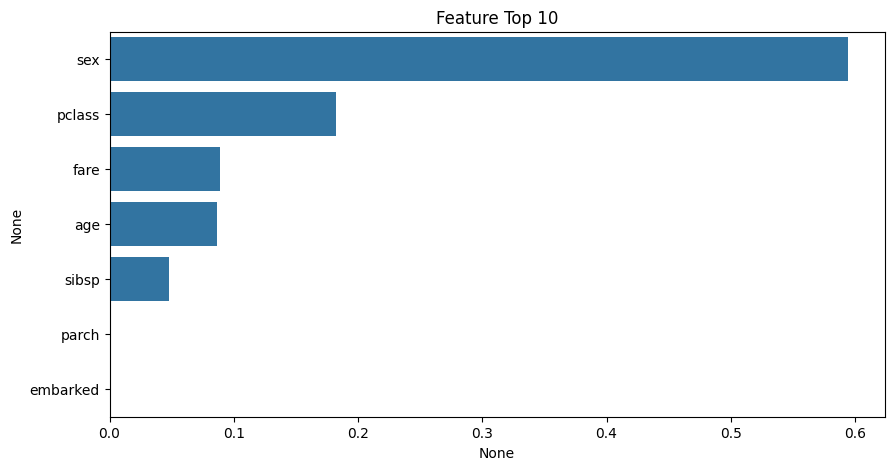

In [704]:
plt.figure(figsize = (10, 5))
plt.title('Feature Top 10')
sns.barplot(x = feature_top10, y = feature_top10.index)
plt.show()

In [705]:
label_name = ['Dead', 'Survived']
feature_name = X_train.columns.tolist()
#데이터 이름명시

In [706]:
from sklearn.tree import export_graphviz

#export_graphviz()의 호출 결과로 out_file로 지정된 tree.dot 파일 생성
export_graphviz(best_dt_titanic, out_file = "./11장_data/tree.dot", class_names = label_name, feature_names = feature_name, impurity = True, filled = True)

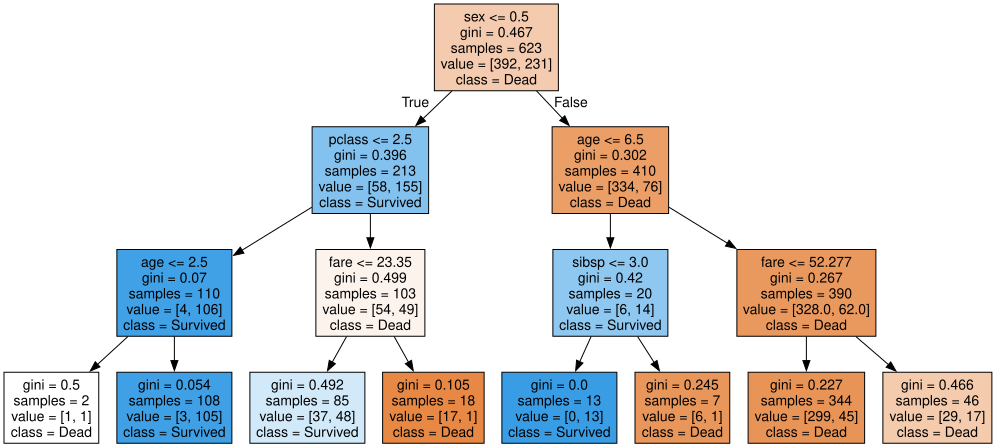

In [707]:
import graphviz

#위에서 생성된 tree.dot 파일을 Graphviz가 읽어서 시각화
with open("./11장_data/tree.dot") as f:
    dot_graph = f.read()
    
graphviz.Source(dot_graph)

In [708]:
#정확도가 제일 높았던 max_depth 3으로 결정 트리를 그렸는데
#gini 값이 0.5일때 맞는지 아닌지 모른다는 것인데
#0.054등 순도가 매우 높은곳이 있는 반면 0.5에 근사하는 값들이 많은것을 보아 분류가 잘되는 곳은 잘되고 안되는곳은 아예 안되는 형태임을 알 수 있다.

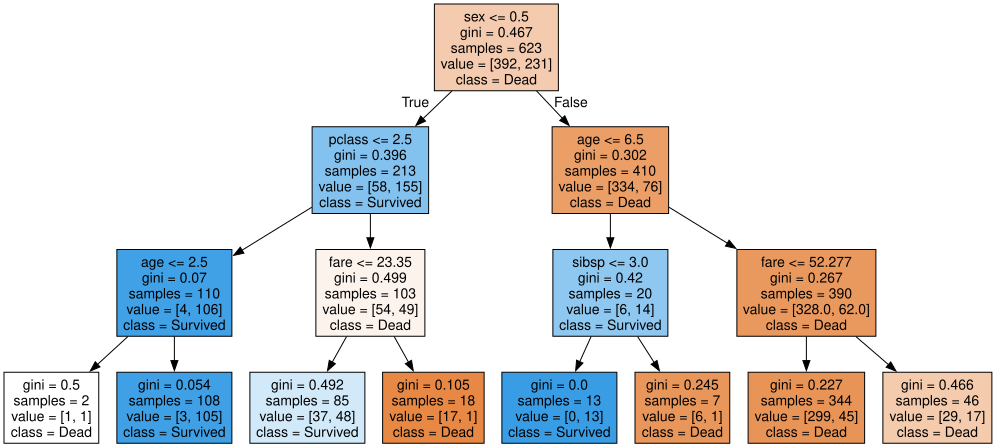

In [709]:
import graphviz

#위에서 생성된 tree.dot 파일을 Graphviz가 읽어서 시각화
with open("./11장_data/tree.dot") as f:
    dot_graph = f.read()
    
graphviz.Source(dot_graph)

In [710]:
#예측 정확도는 낮지만 gini가 0.5에 근사한 값들의 샘플수가 확실히 낮아진것을 확인할 수 있다.
#예측 정확도만 믿고 모델을 돌리면 안된다.

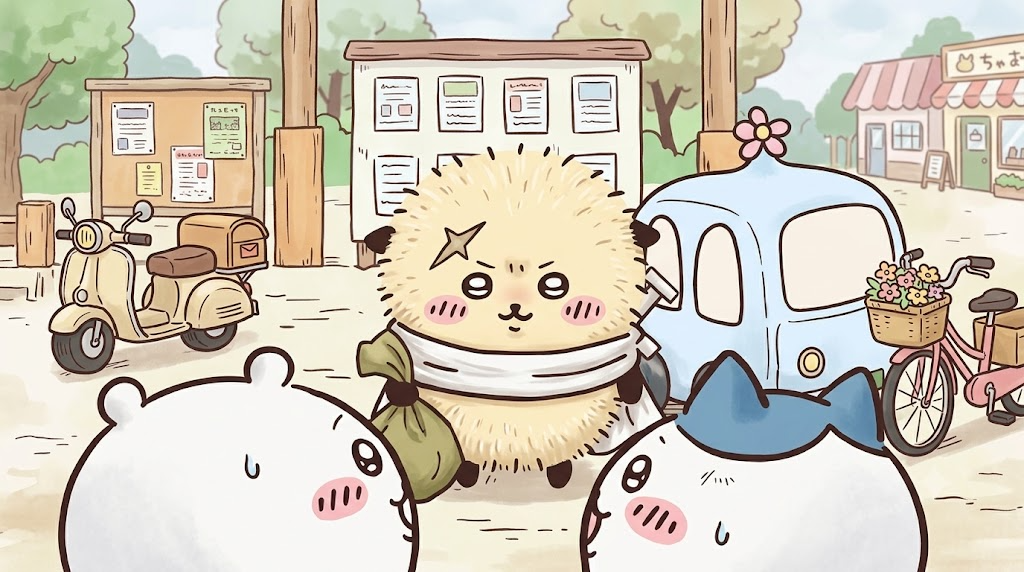

In [ ]:
import glob
all_files = glob.glob("./12장_data/201[89].csv")

# 파일들을 읽어서 리스트에 담기
df_list = [pd.read_csv(filename) for filename in all_files]

# 모든 데이터프레임을 하나로 합친 뒤, 평균 계산하기
# concat으로 합친 후 groupby해서 평균 적용
combined_df = pd.concat(df_list)
mean_df = combined_df.groupby('Country or region').mean(numeric_only=True)

mean_df.to_csv("result_mean.csv", index=True)

성공적으로 저장되었습니다!


In [712]:
happy_df = pd.read_csv("./12장_data/result_mean.csv")

In [713]:
happy_df.describe()

,Overall rank,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
count,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000
mean,79.343750,5.372500,0.892956,1.208387,0.655753,0.419778,0.182641,0.110919
std,45.018277,1.109938,0.392695,0.296900,0.246246,0.153292,0.095577,0.093398
min,1.000000,3.053500,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,40.750000,4.476625,0.604125,1.050125,0.479250,0.337250,0.112250,0.051375
50%,79.250000,5.370000,0.948500,1.242500,0.719500,0.444750,0.176000,0.084750
75%,120.250000,6.152125,1.207750,1.456625,0.831250,0.532125,0.243250,0.136875
max,155.000000,7.700500,1.799500,1.634000,1.076000,0.677500,0.582000,0.455000


In [714]:
happy_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Country or region             160 non-null    object 
 1   Overall rank                  160 non-null    float64
 2   Score                         160 non-null    float64
 3   GDP per capita                160 non-null    float64
 4   Social support                160 non-null    float64
 5   Healthy life expectancy       160 non-null    float64
 6   Freedom to make life choices  160 non-null    float64
 7   Generosity                    160 non-null    float64
 8   Perceptions of corruption     160 non-null    float64
dtypes: float64(8), object(1)
memory usage: 11.4+ KB


In [715]:
happy_df.isnull().sum()

Country or region               0
Overall rank                    0
Score                           0
GDP per capita                  0
Social support                  0
Healthy life expectancy         0
Freedom to make life choices    0
Generosity                      0
Perceptions of corruption       0
dtype: int64

In [716]:
happy_df = happy_df.sort_values(by='Score', ascending=False)

In [717]:
happy_df['Overall rank'] = range(1, len(happy_df) + 1)

In [718]:
happy_df.head(3)

,Country or region,Overall rank,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
45,Finland,1,7.7005,1.3225,1.5895,0.9300,0.6385,0.1775,0.3930
38,Denmark,2,7.5775,1.3670,1.5815,0.9320,0.6375,0.2680,0.4090
108,Norway,3,7.5740,1.4720,1.5820,0.9445,0.6445,0.2785,0.3405


In [719]:
summary_df = pd.DataFrame({
    'Counts': [
        happy_df['Country or region'].nunique(),  # 국가 수
        happy_df['Overall rank'].nunique(),       # 고유한 순위 개수
        len(happy_df)                             # 전체 데이터 행 수 (데이터 개수)
    ]
}, index=['Country', 'Rank', 'Total Records'])

# 결과 확인
print(summary_df)

               Counts
Country           160
Rank              160
Total Records     160


In [720]:
happy_df['Country or region'].value_counts()

Country or region
Finland                     1
Denmark                     1
Norway                      1
Iceland                     1
Switzerland                 1
                           ..
Yemen                       1
Burundi                     1
Tanzania                    1
Central African Republic    1
South Sudan                 1
Name: count, Length: 160, dtype: int64

In [721]:
#행복 점수 / 관용 해보기
happy_df['irony'] = happy_df['Score'] / happy_df['Generosity']

In [722]:
print(happy_df.describe().loc['max'])
print(happy_df.isin([np.inf, -np.inf]).sum())
happy_df = happy_df.replace([np.inf, -np.inf], np.nan)
happy_df = happy_df.fillna(0)
print(happy_df.isin([np.inf, -np.inf]).sum())

Overall rank                    160.0000
Score                             7.7005
GDP per capita                    1.7995
Social support                    1.6340
Healthy life expectancy           1.0760
Freedom to make life choices      0.6775
Generosity                        0.5820
Perceptions of corruption         0.4550
irony                                inf
Name: max, dtype: float64
Country or region               0
Overall rank                    0
Score                           0
GDP per capita                  0
Social support                  0
Healthy life expectancy         0
Freedom to make life choices    0
Generosity                      0
Perceptions of corruption       0
irony                           1
dtype: int64
Country or region               0
Overall rank                    0
Score                           0
GDP per capita                  0
Social support                  0
Healthy life expectancy         0
Freedom to make life choices    0
Generosity    

In [723]:
scaler = StandardScaler()
happy_df['irony'] = pd.to_numeric(happy_df['irony'], errors='coerce')
happy_df['irony'] = scaler.fit_transform(happy_df[['irony']])

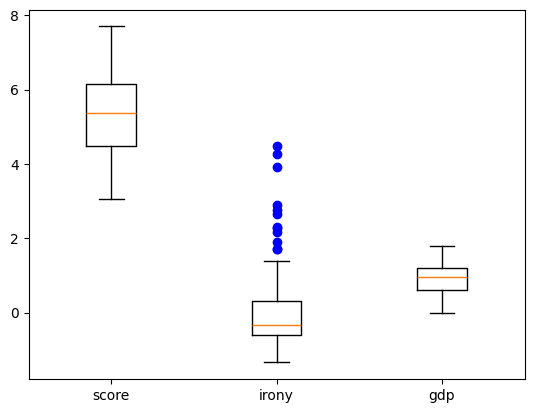

In [724]:
fig, ax = plt.subplots()
ax.boxplot([happy_df['Score'], happy_df['irony'], happy_df['GDP per capita']], sym = 'bo')
plt.xticks([1, 2, 3], ['score', 'irony','gdp'])
plt.show()

In [725]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

In [726]:
happy_df['irony_log'] = np.log1p(happy_df['irony'])
happy_df['Score_log'] = np.log1p(happy_df['Score'])
happy_df['GDP_log'] = np.log1p(happy_df['GDP per capita'])
happy_df = happy_df.fillna(0)
X_features = happy_df[['Score_log', 'irony_log', 'GDP_log']].values

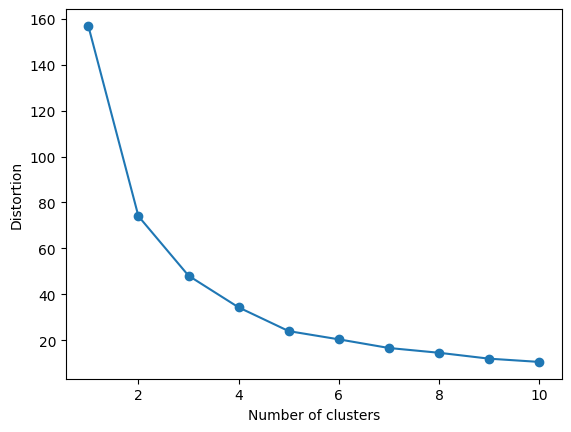

In [ ]:
#엘보우 기법 / y축은 클러스터 내 응집도 
distortions = []

for i in range(1, 11):
    kmeans_i = KMeans(n_clusters = i, #모델 생성
                      random_state = 0, 
                      n_init='auto') #서로 다른 초기 중심점으로 여러 번 실행 후 가장 좋은 결과 선택
    kmeans_i.fit(X_features) #모델 훈련
    distortions.append(kmeans_i.inertia_) 
    # inertia : 각 클러스터 중심점과 해당 클러스터에 속한 데이터 간 거리의 제곱 합
    # 값이 작을수록 군집 내부가 조밀함 -> 군집이 잘 묶였다고 판단
    
plt.plot(range(1,11), distortions, marker = 'o')
plt.xlabel('Number of clusters')
plt.ylabel('Distortion')
plt.show()
#과적합 때문에 너무 나누는건 좋지 않다

In [728]:
kmeans = KMeans(n_clusters=3, random_state=0, n_init='auto') #모델 생성

#모델 학습과 결과 예측(클러스터 레이블 생성)
Y_labels = kmeans.fit_predict(X_features)

In [729]:
happy_df['ClusterLabel'] = Y_labels

happy_df.head() #작업 확인용 출력

,Country or region,Overall rank,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,irony,irony_log,Score_log,GDP_log,ClusterLabel
45,Finland,1,7.7005,1.3225,1.5895,0.9300,0.6385,0.1775,0.3930,0.100604,0.095859,2.163380,0.842644,0
38,Denmark,2,7.5775,1.3670,1.5815,0.9320,0.6375,0.2680,0.4090,-0.402566,-0.515112,2.149142,0.861623,2
108,Norway,3,7.5740,1.4720,1.5820,0.9445,0.6445,0.2785,0.3405,-0.438486,-0.577118,2.148734,0.905028,2
59,Iceland,4,7.4945,1.3615,1.6340,0.9700,0.6340,0.3535,0.1280,-0.638132,-1.016477,2.139419,0.859297,2
137,Switzerland,5,7.4835,1.4360,1.5375,0.9895,0.6160,0.2595,0.3500,-0.383787,-0.484162,2.138123,0.890357,2


In [730]:
from matplotlib import cm

def silhouetteViz(n_cluster, X_features):
    kmeans = KMeans(n_clusters = n_cluster, random_state = 0, n_init='auto')
    Y_labels = kmeans.fit_predict(X_features) 
    # 학습과 클러스터 라벨 예측을 한번에 해줌
    
    #실루엣 값 계산
    #범위는 -1 ~ +1 사이 값 / 0에 가까우면 : 모호 / +1에 가까우면 good / -1에 가까우면 다시 클러스터링 진행
    silhouette_values = silhouette_samples(X_features, Y_labels, metric = 'euclidean')

#클러스터별 막대가 겹치지 않기위해 시작점 정의
    y_ax_lower, y_ax_upper = 0, 0
    y_ticks = []
    
    #군집별로 실루엣 값 모아서 정렬하고 그리기
    for c in range(n_cluster):
        # 클러스터 c에 속한 데이터들의 실루엣 값만 뽑아 정렬
        c_silhouettes = silhouette_values[Y_labels == c]
        c_silhouettes.sort()
        #그래프에서 각 클러스터 이미지 세로 위치를 잡기 위한 인덱스
        y_ax_upper += len(c_silhouettes)
        color = cm.jet(float(c) / n_cluster)
        #가로로 누운 막대그래프
        plt.barh( range(y_ax_lower, y_ax_upper), c_silhouettes, height= 1.0, edgecolor = 'none', color = color)
        y_ticks.append((y_ax_lower + y_ax_upper) / 2.)
        y_ax_lower += len(c_silhouettes)
    
    # 평균 실루엣 표시 : 빨간 점선 = 전체 평균 실루엣 점수   
    # 평균 실루엣 점수(빨간 점선) 일반적으로
    # 0.5 이상: 꽤 괜찮은 군집(데이터에 따라 다름)
    # 0.2~0.5: 애매하지만 의미 있을 수 있음
    # 0.2 미만: 군집 구조가 약할 수 있음 
    silhouette_avg = np.mean(silhouette_values)
    #수직선 그리는 함수
    plt.axvline(silhouette_avg, color = 'red', linestyle = '--')
    plt.title( 'Number of Cluster : '+ str(n_cluster) + '\n' +'Silhouette Score : '+ str(round(silhouette_avg,3)))
    plt.yticks(y_ticks, range(n_cluster))
    plt.xticks([0, 0.2, 0.4, 0.6, 0.8, 1])
    plt.ylabel('Cluster')
    plt.xlabel('Silhouette coefficient')
    plt.tight_layout()
    plt.show()

In [731]:
def clusterScatter(n_cluster, X_features):
    c_colors = []
    kmeans = KMeans(n_clusters = n_cluster, random_state = 0, n_init='auto')
    Y_labels = kmeans.fit_predict(X_features)
    
    for i in range(n_cluster):
        c_color = cm.jet(float(i) / n_cluster) #클러스터의 색상 설정
        c_colors.append(c_color)
        #클러스터의 데이터 분포를 동그라미로 시각화
        plt.scatter( X_features[Y_labels == i,0], X_features[Y_labels== i,1], 
                    marker = 'o', color = c_color, edgecolor= 'black', s = 50, label = 'cluster '+ str(i))

    #각 클러스터의 중심점을 삼각형으로 표시
    for i in range(n_cluster):
        plt.scatter(kmeans.cluster_centers_[i,0], kmeans.cluster_centers_[i,1], marker = '^', color = c_colors[i],
                    edgecolor = 'w', s = 200)
        
    plt.legend()
    plt.grid()
    plt.tight_layout()
    plt.show()

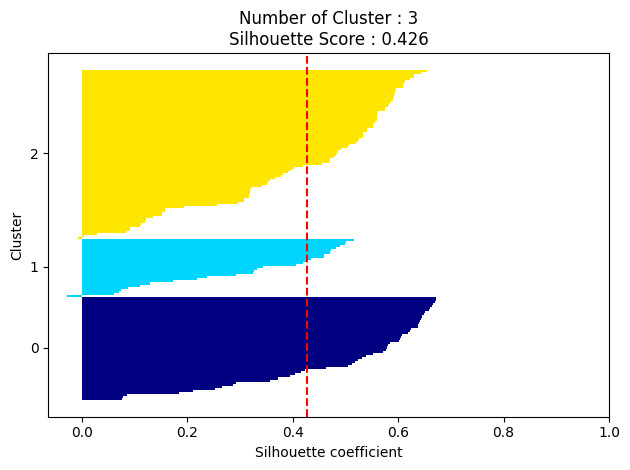

In [732]:
silhouetteViz(3, X_features)

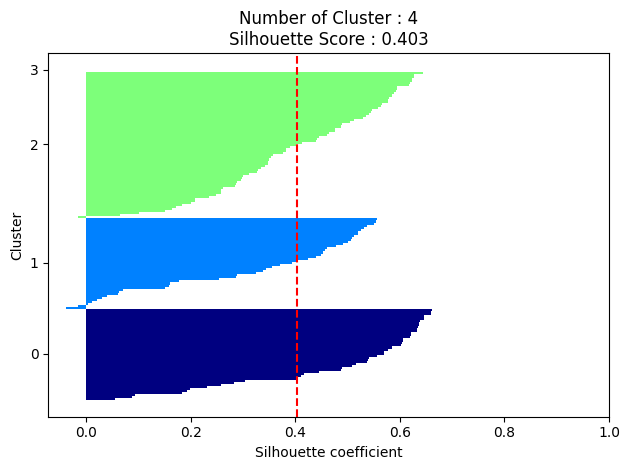

In [747]:
silhouetteViz(4, X_features)

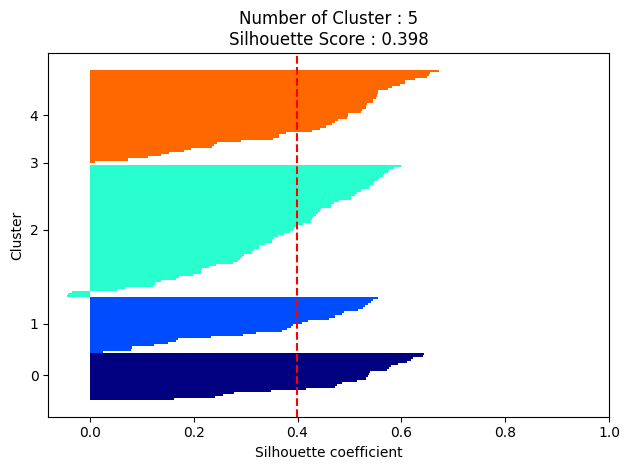

In [734]:
silhouetteViz(5, X_features)

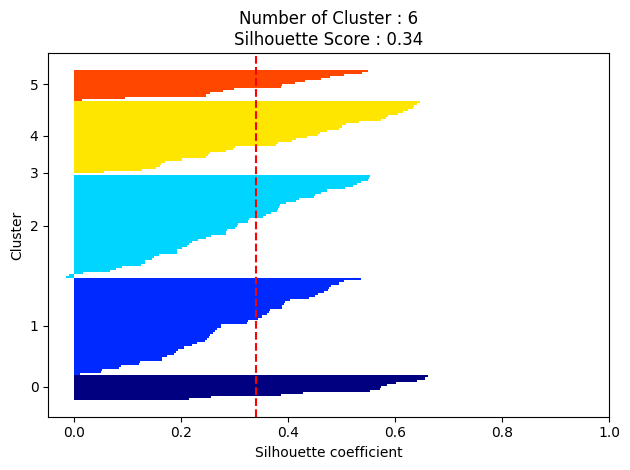

In [735]:
silhouetteViz(6, X_features)

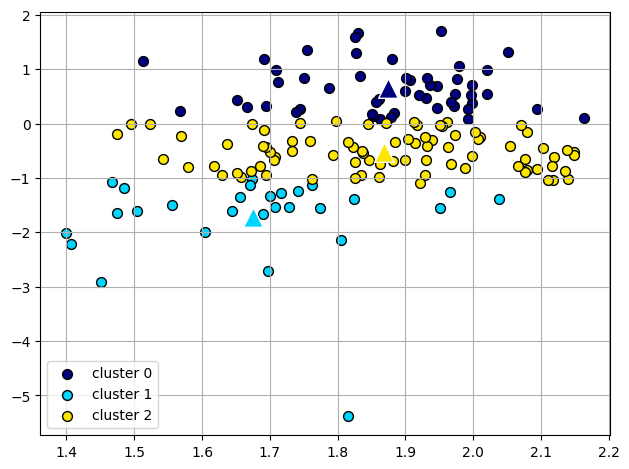

In [736]:
clusterScatter(3, X_features)

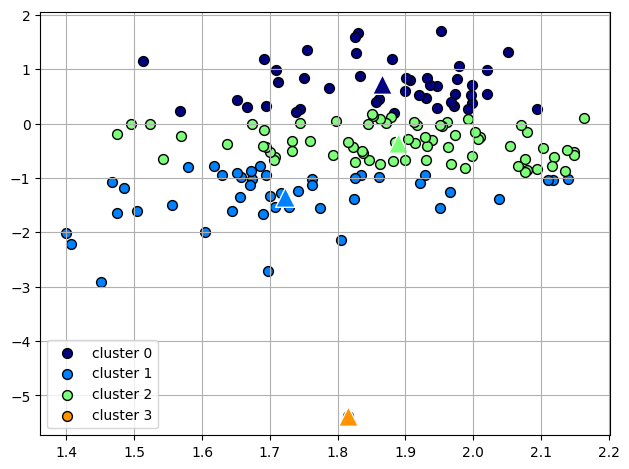

In [737]:
clusterScatter(4, X_features)

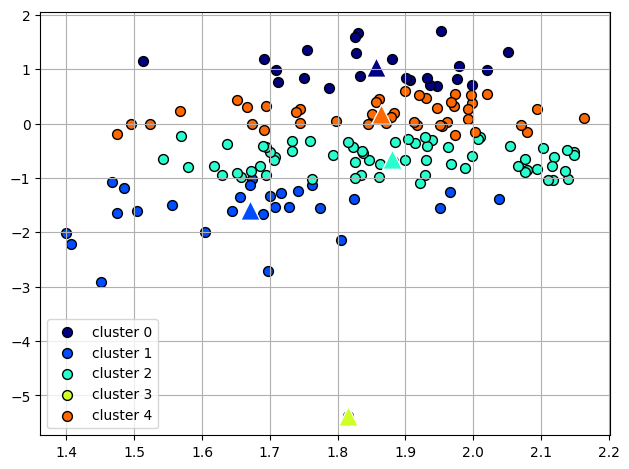

In [738]:
clusterScatter(5, X_features)

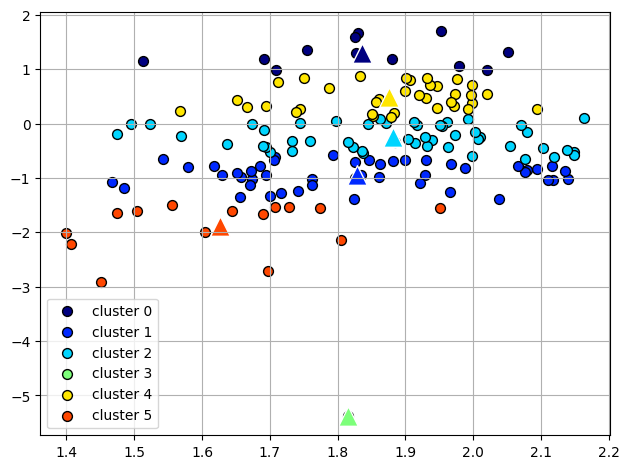

In [739]:
clusterScatter(6, X_features)

In [740]:
best_cluster = 3
kmeans = KMeans(n_clusters = best_cluster, random_state = 0, n_init='auto')
Y_labels = kmeans.fit_predict(X_features)

In [741]:
happy_df['ClusterLabel'] = Y_labels

happy_df.head()  #작업 확인용 출력

,Country or region,Overall rank,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,irony,irony_log,Score_log,GDP_log,ClusterLabel
45,Finland,1,7.7005,1.3225,1.5895,0.9300,0.6385,0.1775,0.3930,0.100604,0.095859,2.163380,0.842644,0
38,Denmark,2,7.5775,1.3670,1.5815,0.9320,0.6375,0.2680,0.4090,-0.402566,-0.515112,2.149142,0.861623,2
108,Norway,3,7.5740,1.4720,1.5820,0.9445,0.6445,0.2785,0.3405,-0.438486,-0.577118,2.148734,0.905028,2
59,Iceland,4,7.4945,1.3615,1.6340,0.9700,0.6340,0.3535,0.1280,-0.638132,-1.016477,2.139419,0.859297,2
137,Switzerland,5,7.4835,1.4360,1.5375,0.9895,0.6160,0.2595,0.3500,-0.383787,-0.484162,2.138123,0.890357,2


In [742]:
happy_df.to_csv('./12장_data/happy_Cluster.csv')

In [743]:
happy_df.groupby('ClusterLabel')['Country or region'].count()

ClusterLabel
0    50
1    28
2    82
Name: Country or region, dtype: int64

In [744]:
#로그로 변환해 줬던 값들 다 드랍해준다.
happy_cluster_df = happy_df.drop(['irony_log', 'Score_log', 'GDP_log'],axis = 1, inplace = False)

In [745]:
happy_cluster_df.head(3)

,Country or region,Overall rank,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,irony,ClusterLabel
45,Finland,1,7.7005,1.3225,1.5895,0.9300,0.6385,0.1775,0.3930,0.100604,0
38,Denmark,2,7.5775,1.3670,1.5815,0.9320,0.6375,0.2680,0.4090,-0.402566,2
108,Norway,3,7.5740,1.4720,1.5820,0.9445,0.6445,0.2785,0.3405,-0.438486,2


In [ ]:
happy_cluster_df.groupby('ClusterLabel').mean(numeric_only=True).round(2)
#irnoy값이 크면 클수록 관용이 낮다는 것인데 돈많은 사람들이 관용을 덜 베푼`다

,Overall rank,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,irony
ClusterLabel,,,,,,,,,
0,70.70,5.57,1.04,1.31,0.73,0.41,0.09,0.09,1.13
1,119.82,4.41,0.48,0.97,0.47,0.43,0.27,0.11,-0.79
2,73.05,5.58,0.95,1.23,0.68,0.42,0.21,0.13,-0.42


In [750]:
print(happy_df[['Score','irony', 'Generosity']].corr())

               Score     irony  Generosity
Score       1.000000  0.132486    0.108022
irony       0.132486  1.000000   -0.710449
Generosity  0.108022 -0.710449    1.000000
